# PINN Backbone: 1D Heat Diffusion

**Post-graduate exercise -- IMW 2026.**

This is a *skeleton* notebook. The data-sampling, plotting, and validation code is provided; the core PINN logic is left for you to fill in as `TODO` blocks. Full mathematical background is in `pinn_heat_equation.tex` -- read it first.

PDE: $u_t = \alpha\, u_{xx}$ on $x \in [0,1]$, $t \in [0,1]$.
IC: $u(x,0) = \sin(\pi x)$. BC: $u(0,t) = u(1,t) = 0$.
Exact solution (for validation only): $u(x,t) = \sin(\pi x)\, e^{-\alpha \pi^2 t}$.

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

ALPHA = 0.1
L = 1.0
T = 1.0

def exact_solution(x, t):
    """Ground-truth analytical solution -- validation only, do not use during training."""
    return np.sin(np.pi * x) * np.exp(-ALPHA * (np.pi ** 2) * t)

## 1. Sample training points (provided)

Interior collocation points (`x_f, t_f`), initial-condition points (`x_ic, t_ic, u_ic`), and boundary points (`x_bc_left, x_bc_right, t_bc, u_bc`). See Eqs. (7)-(9) in the tex document.

In [ ]:
N_COLLOCATION = 2000
N_IC = 200
N_BC = 200

x_f = np.random.uniform(0, L, (N_COLLOCATION, 1))
t_f = np.random.uniform(0, T, (N_COLLOCATION, 1))

x_ic = np.random.uniform(0, L, (N_IC, 1))
t_ic = np.zeros((N_IC, 1))
u_ic = np.sin(np.pi * x_ic)

t_bc = np.random.uniform(0, T, (N_BC, 1))
x_bc_left = np.zeros((N_BC, 1))
x_bc_right = np.ones((N_BC, 1))
u_bc = np.zeros((N_BC, 1))

to_tf = lambda arr: tf.convert_to_tensor(arr, dtype=tf.float32)
x_f, t_f = to_tf(x_f), to_tf(t_f)
x_ic, t_ic, u_ic = to_tf(x_ic), to_tf(t_ic), to_tf(u_ic)
x_bc_left, x_bc_right, t_bc, u_bc = to_tf(x_bc_left), to_tf(x_bc_right), to_tf(t_bc), to_tf(u_bc)

print(f"Collocation points: {x_f.shape[0]}, IC points: {x_ic.shape[0]}, BC points/side: {x_bc_left.shape[0]}")

Collocation points: 2000, IC points: 200, BC points/side: 200


## 2. TODO: build the network

Build a fully-connected MLP: 2 inputs `(x, t)` -> several hidden layers -> 1 output `u`.

Requirements (see Section 4 of the tex document):
- Use a **smooth** activation (`tanh`), not ReLU -- the physics loss needs a nonzero second derivative.
- Suggested defaults: 4 hidden layers, 40 units each, `glorot_normal` initializer.
- Input shape `(2,)`, output shape `(1,)`.

In [ ]:
def build_pinn(n_layers=4, n_units=40):
    inputs = tf.keras.Input(shape=(2,))
    h = inputs
    for _ in range(n_layers):
        h = tf.keras.layers.Dense(
            n_units, activation="tanh", kernel_initializer="glorot_normal"
        )(h)
    outputs = tf.keras.layers.Dense(1, kernel_initializer="glorot_normal")(h)
    return tf.keras.Model(inputs, outputs)

model = build_pinn()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 40)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         1,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 40)             │         1,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 40)             │         1,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            41 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,081 (19.85 KB)

 Trainable params: 5,081 (19.85 KB)

 Non-trainable params: 0 (0.00 B)

## 3. TODO: PDE residual via automatic differentiation

Implement Eq. (6) from the tex document:

$$ f_\theta(x,t) = \frac{\partial u_\theta}{\partial t} - \alpha \frac{\partial^2 u_\theta}{\partial x^2} $$

Hints:
- You need **two nested** `tf.GradientTape(persistent=True)` contexts: the outer one to get the second derivative `u_xx`, the inner one to get first derivatives `u_x` and `u_t`.
- Both tapes must `watch(x)` and `watch(t)` explicitly, since `x` and `t` are plain tensors, not `tf.Variable`s.
- Remember to `del` persistent tapes when done to free memory.

In [ ]:
def pde_residual(model, x, t):
    """Returns f = u_t - ALPHA * u_xx at the given (x, t) points."""
    with tf.GradientTape(persistent=True) as tape2:
        tape2.watch([x, t])
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch([x, t])
            u = model(tf.concat([x, t], axis=1))
        u_x = tape1.gradient(u, x)
        u_t = tape1.gradient(u, t)
    u_xx = tape2.gradient(u_x, x)
    del tape1, tape2
    return u_t - ALPHA * u_xx

## 4. TODO: assemble the total loss and training step

Implement Eqs. (7)-(10): PDE residual loss + IC loss + BC loss (equal weights = 1 to start). Use `tf.reduce_mean(tf.square(...))` for each term.

In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

@tf.function
def train_step():
    with tf.GradientTape() as tape:
        # physics loss
        f_pred = pde_residual(model, x_f, t_f)
        loss_pde = tf.reduce_mean(tf.square(f_pred))

        # initial-condition loss
        u_ic_pred = model(tf.concat([x_ic, t_ic], axis=1))
        loss_ic = tf.reduce_mean(tf.square(u_ic_pred - u_ic))

        # boundary-condition loss (both x=0 and x=1)
        u_bc_left_pred = model(tf.concat([x_bc_left, t_bc], axis=1))
        u_bc_right_pred = model(tf.concat([x_bc_right, t_bc], axis=1))
        loss_bc = tf.reduce_mean(tf.square(u_bc_left_pred - u_bc)) + \
                  tf.reduce_mean(tf.square(u_bc_right_pred - u_bc))

        # total loss (equal weights = 1, per Eq. 10 baseline)
        loss = loss_pde + loss_ic + loss_bc

    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss, loss_pde, loss_ic, loss_bc

## 5. Training loop (provided)

Once cells 2-4 above are implemented, this should run and the loss components should decrease. If `loss_pde` stays flat while `loss_ic`/`loss_bc` drop to zero, check your residual implementation (Section 3) first -- that is the most common bug.

In [ ]:
EPOCHS = 5000
history = {'loss': [], 'loss_pde': [], 'loss_ic': [], 'loss_bc': []}

for epoch in range(EPOCHS):
    loss, loss_pde, loss_ic, loss_bc = train_step()
    history['loss'].append(float(loss))
    history['loss_pde'].append(float(loss_pde))
    history['loss_ic'].append(float(loss_ic))
    history['loss_bc'].append(float(loss_bc))
    if epoch % 500 == 0:
        print(f"Epoch {epoch:5d} | total {loss:.2e} | pde {loss_pde:.2e} | "
              f"ic {loss_ic:.2e} | bc {loss_bc:.2e}")

Epoch     0 | total 4.99e-01 | pde 1.40e-02 | ic 4.79e-01 | bc 5.96e-03
Epoch   500 | total 7.99e-04 | pde 3.13e-04 | ic 1.69e-04 | bc 3.18e-04
Epoch  1000 | total 3.35e-04 | pde 1.37e-04 | ic 6.53e-05 | bc 1.32e-04
Epoch  1500 | total 2.91e-04 | pde 1.11e-04 | ic 3.06e-05 | bc 1.49e-04
Epoch  2000 | total 1.20e-04 | pde 7.08e-05 | ic 1.16e-05 | bc 3.71e-05
Epoch  2500 | total 9.58e-05 | pde 5.27e-05 | ic 1.34e-05 | bc 2.96e-05
Epoch  3000 | total 5.89e-05 | pde 3.87e-05 | ic 3.13e-06 | bc 1.71e-05
Epoch  3500 | total 1.69e-03 | pde 1.37e-04 | ic 3.55e-04 | bc 1.20e-03
Epoch  4000 | total 3.22e-05 | pde 2.23e-05 | ic 1.02e-06 | bc 8.89e-06
Epoch  4500 | total 2.62e-05 | pde 1.78e-05 | ic 5.11e-07 | bc 7.90e-06


## 6. Diagnostics and validation (provided)

Run this once training works. Do not modify -- use it to check your implementation.

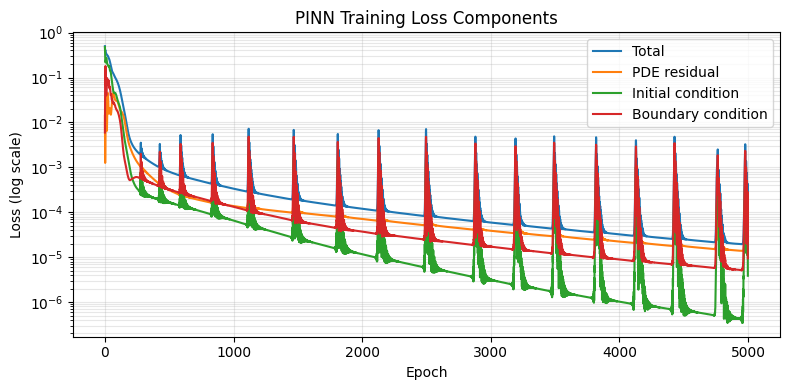

Max absolute error: 1.1184e-02
Mean absolute error: 6.5494e-03


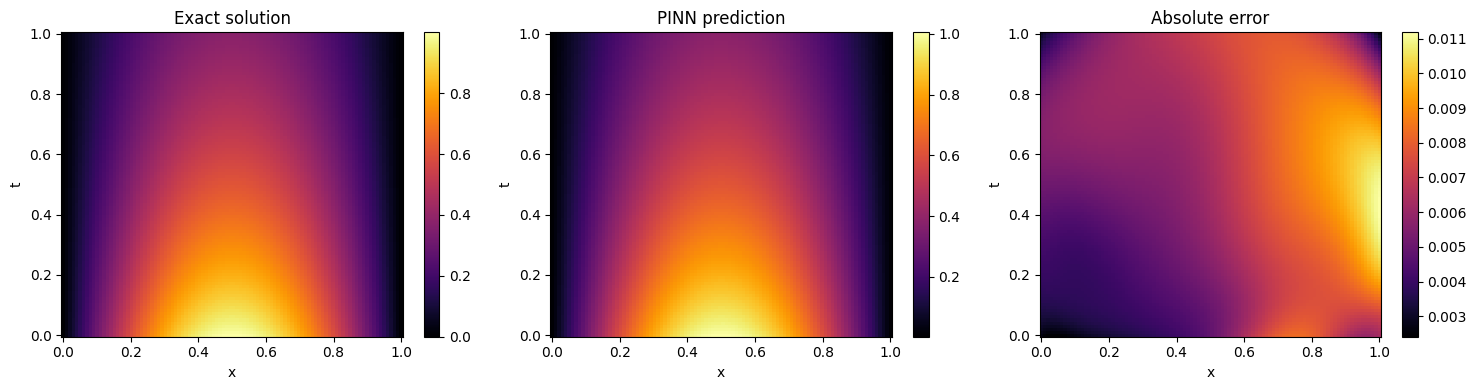

In [ ]:
plt.figure(figsize=(8, 4))
plt.semilogy(history['loss'], label='Total')
plt.semilogy(history['loss_pde'], label='PDE residual')
plt.semilogy(history['loss_ic'], label='Initial condition')
plt.semilogy(history['loss_bc'], label='Boundary condition')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.title('PINN Training Loss Components')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

n_grid = 100
x_grid = np.linspace(0, L, n_grid)
t_grid = np.linspace(0, T, n_grid)
X, Tm = np.meshgrid(x_grid, t_grid)
xt_flat = np.stack([X.flatten(), Tm.flatten()], axis=1).astype(np.float32)
u_pred = model(xt_flat).numpy().reshape(n_grid, n_grid)
u_exact = exact_solution(X, Tm)
abs_error = np.abs(u_pred - u_exact)
print(f"Max absolute error: {abs_error.max():.4e}")
print(f"Mean absolute error: {abs_error.mean():.4e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(axes, [u_exact, u_pred, abs_error],
                           ['Exact solution', 'PINN prediction', 'Absolute error']):
    im = ax.pcolormesh(X, Tm, data, shading='auto', cmap='inferno')
    ax.set_xlabel('x'); ax.set_ylabel('t'); ax.set_title(title)
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 7. Snapshot comparison at fixed times (provided)

A second, complementary view of the same result: fixed-time slices of $u(x,t)$, exact vs. PINN, overlaid. Useful for spotting whether errors are concentrated near $t=0$ (an IC-fitting problem) or grow over time (an accumulating-residual problem).

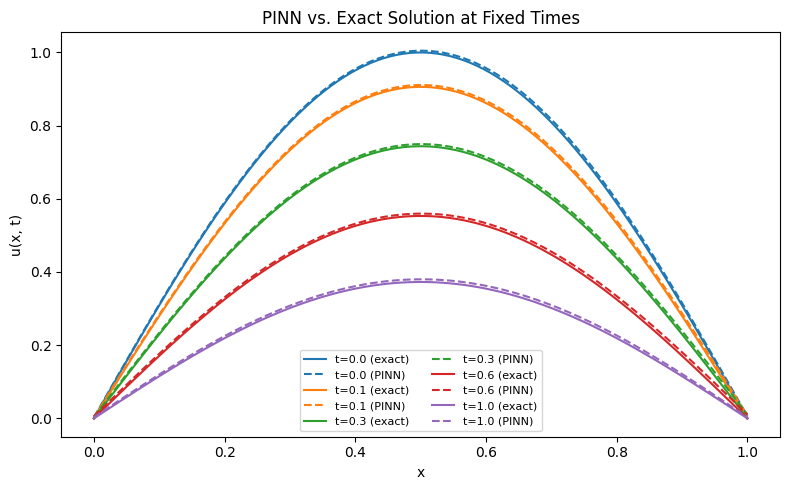

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for t_snap in [0.0, 0.1, 0.3, 0.6, 1.0]:
    xt_snap = np.stack([x_grid, np.full_like(x_grid, t_snap)], axis=1).astype(np.float32)
    u_snap_pred = model(xt_snap).numpy().flatten()
    u_snap_exact = exact_solution(x_grid, t_snap)
    line, = ax.plot(x_grid, u_snap_exact, '-', label=f't={t_snap} (exact)')
    ax.plot(x_grid, u_snap_pred, '--', color=line.get_color(), label=f't={t_snap} (PINN)')
ax.set_xlabel('x')
ax.set_ylabel('u(x, t)')
ax.set_title('PINN vs. Exact Solution at Fixed Times')
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## Exercise A: Sensitivity to collocation density

This exercise explores the model's sensitivity to collocation density by varying $N_f \in \{100, 500, 2000, 5000\}$. The goal is to plot the maximum absolute error against the exact solution as a function of $N_f$.

Training with N_f = 100...
Training with N_f = 500...
Training with N_f = 2000...
Training with N_f = 5000...


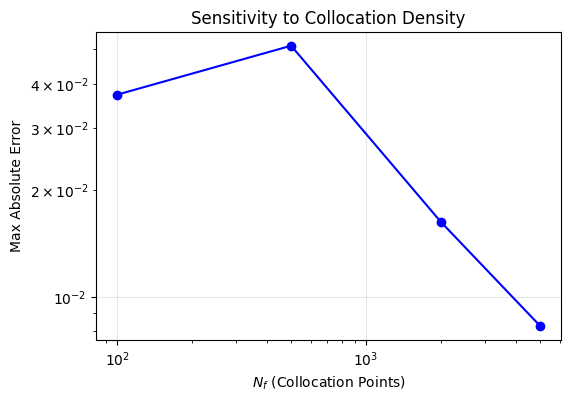

In [ ]:
# Exercise A Implementation
N_f_list = [100, 500, 2000, 5000]
max_errors = []

for n_f in N_f_list:
    print(f"Training with N_f = {n_f}...")

    # 1. Sample data
    x_f_a = tf.convert_to_tensor(np.random.uniform(0, L, (n_f, 1)), dtype=tf.float32)
    t_f_a = tf.convert_to_tensor(np.random.uniform(0, T, (n_f, 1)), dtype=tf.float32)

    # 2. Build model and optimizer
    model_a = build_pinn()
    optimizer_a = tf.keras.optimizers.Adam(learning_rate=1e-3)

    # 3. Training step function
    @tf.function
    def train_step_a():
        with tf.GradientTape() as tape:
            # PDE loss
            f_pred = pde_residual(model_a, x_f_a, t_f_a)
            loss_pde = tf.reduce_mean(tf.square(f_pred))

            # IC loss
            u_ic_pred = model_a(tf.concat([x_ic, t_ic], axis=1))
            loss_ic = tf.reduce_mean(tf.square(u_ic_pred - u_ic))

            # BC loss
            u_bc_left_pred = model_a(tf.concat([x_bc_left, t_bc], axis=1))
            u_bc_right_pred = model_a(tf.concat([x_bc_right, t_bc], axis=1))
            loss_bc = tf.reduce_mean(tf.square(u_bc_left_pred - u_bc)) + \
                      tf.reduce_mean(tf.square(u_bc_right_pred - u_bc))

            loss = loss_pde + loss_ic + loss_bc

        grads = tape.gradient(loss, model_a.trainable_variables)
        optimizer_a.apply_gradients(zip(grads, model_a.trainable_variables))
        return loss

    # 4. Train
    for epoch in range(2000): # Reduced epochs for rapid evaluation
        train_step_a()

    # 5. Evaluate max error
    xt_flat = np.stack([X.flatten(), Tm.flatten()], axis=1).astype(np.float32)
    u_pred = model_a(xt_flat).numpy().reshape(n_grid, n_grid)
    abs_error = np.abs(u_pred - u_exact)
    max_errors.append(abs_error.max())

# Plot results
plt.figure(figsize=(6, 4))
plt.plot(N_f_list, max_errors, marker='o', linestyle='-', color='b')
plt.xlabel('$N_f$ (Collocation Points)')
plt.ylabel('Max Absolute Error')
plt.title('Sensitivity to Collocation Density')
plt.grid(True, alpha=0.3)
plt.xscale('log')
plt.yscale('log')
plt.show()

Although the provided plot shows that accuracy continues to improve significantly as collocation points ($N_f$) increase, the error reduction will eventually reach a horizontal plateau. At low densities, the network may "overfit" to specific points, creating oscillations that satisfy the residual loss while failing to accurately capture the true solution. As sampling density increases, these collocation points form a dense mesh that forces the network to learn the physical solution. However, accuracy will ultimately be constrained by the network's capacity and optimizer limitations rather than a lack of spatial data. At this final bottleneck, the PDE residual loss will cease to decrease regardless of further increases in collocation density.

## Exercise B: Loss weighting

This exercise introduces weights $(w_f, w_0, w_b)$ to the total loss function to investigate how over-weighting or under-weighting the Initial Conditions and Boundary Conditions affects the solution. We will test configurations of (1, 10, 10) and (1, 100, 100).

Training with weights (w_f=1.0, w_0=10.0, w_b=10.0)...


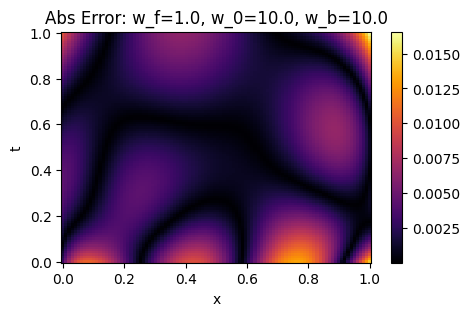

Training with weights (w_f=1.0, w_0=100.0, w_b=100.0)...


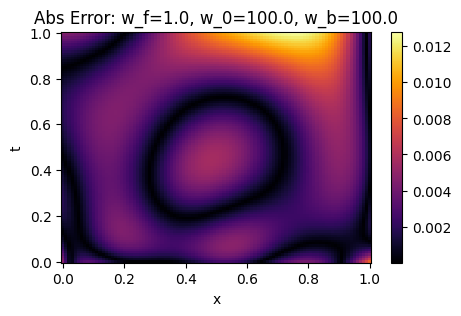

In [ ]:
# Exercise B Implementation
weight_configs = [(1.0, 10.0, 10.0), (1.0, 100.0, 100.0)]

for w_f, w_0, w_b in weight_configs:
    print(f"Training with weights (w_f={w_f}, w_0={w_0}, w_b={w_b})...")

    model_b = build_pinn()
    optimizer_b = tf.keras.optimizers.Adam(learning_rate=1e-3)

    @tf.function
    def train_step_b():
        with tf.GradientTape() as tape:
            # PDE
            f_pred = pde_residual(model_b, x_f, t_f)
            loss_pde = tf.reduce_mean(tf.square(f_pred))
            # IC
            u_ic_pred = model_b(tf.concat([x_ic, t_ic], axis=1))
            loss_ic = tf.reduce_mean(tf.square(u_ic_pred - u_ic))
            # BC
            u_bc_left_pred = model_b(tf.concat([x_bc_left, t_bc], axis=1))
            u_bc_right_pred = model_b(tf.concat([x_bc_right, t_bc], axis=1))
            loss_bc = tf.reduce_mean(tf.square(u_bc_left_pred - u_bc)) + \
                      tf.reduce_mean(tf.square(u_bc_right_pred - u_bc))

            # Weighted loss formulation
            loss = w_f * loss_pde + w_0 * loss_ic + w_b * loss_bc

        grads = tape.gradient(loss, model_b.trainable_variables)
        optimizer_b.apply_gradients(zip(grads, model_b.trainable_variables))
        return loss

    for epoch in range(2000):
        train_step_b()

    u_pred_b = model_b(xt_flat).numpy().reshape(n_grid, n_grid)
    abs_error_b = np.abs(u_pred_b - u_exact)

    # Plot absolute error spatial distribution to observe boundary/interior performance
    plt.figure(figsize=(5, 3))
    im = plt.pcolormesh(X, Tm, abs_error_b, shading='auto', cmap='inferno')
    plt.colorbar(im)
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title(f'Abs Error: w_f={w_f}, w_0={w_0}, w_b={w_b}')
    plt.show()

Adjusting the weights of Initial Condition (IC) and Boundary Condition (BC) terms in a PINN reveals a critical trade-off between boundary precision and interior physical accuracy. Heavily over-weighting these terms forces the network to minimize boundary errors to near zero, as seen in the dark regions at $t=0$, but this over-optimization comes at the expense of the interior solution. Consequently, the optimizer becomes so focused on the boundaries that it under-optimizes the PDE residual, leading to the accumulation of significant errors in the interior and at later time steps. This imbalance highlights a well-known gradient pathology where, by prioritizing boundary perfection, the network fails to adequately learn the underlying physical laws governing the interior domain.

## Exercise C: Inverse problem (parameter estimation)

Instead of hardcoding $\alpha=0.1$, we now treat $\alpha$ as an unknown, trainable scalar. We add noisy synthetic "sensor" observations as an additional data-fit loss term $\mathcal{L}_{data}$ and attempt to recover the true value of $\alpha$.

Epoch    0 | Estimated alpha: 0.5010
Epoch  500 | Estimated alpha: 0.1029
Epoch 1000 | Estimated alpha: 0.1035
Epoch 1500 | Estimated alpha: 0.1042
Epoch 2000 | Estimated alpha: 0.1045
Epoch 2500 | Estimated alpha: 0.1048
Final estimated alpha: 0.1048 (True alpha: 0.1)


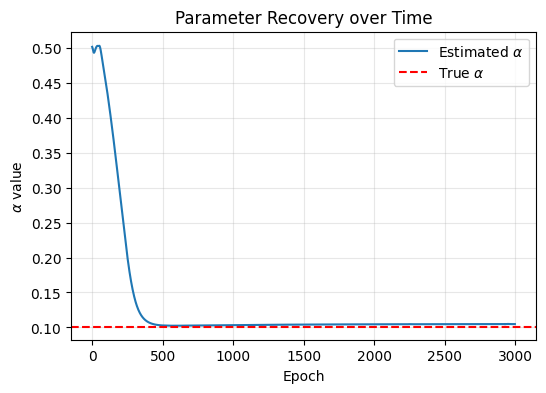

In [ ]:
# Exercise C Implementation
# 1. Generate noisy sensor data
N_SENSOR = 50
x_sensor = np.random.uniform(0, L, (N_SENSOR, 1))
t_sensor = np.random.uniform(0, T, (N_SENSOR, 1))
u_sensor_clean = exact_solution(x_sensor, t_sensor)
u_sensor_noisy = u_sensor_clean + np.random.normal(0, 0.05, (N_SENSOR, 1))

x_sens_tf = tf.convert_to_tensor(x_sensor, dtype=tf.float32)
t_sens_tf = tf.convert_to_tensor(t_sensor, dtype=tf.float32)
u_sens_tf = tf.convert_to_tensor(u_sensor_noisy, dtype=tf.float32)

# 2. Trainable alpha parameter
alpha_pred = tf.Variable(0.5, dtype=tf.float32) # Starting with a bad guess
model_c = build_pinn()
optimizer_c = tf.keras.optimizers.Adam(learning_rate=1e-3)

def pde_residual_inverse(model, x, t, alpha):
    with tf.GradientTape(persistent=True) as tape2:
        tape2.watch([x, t])
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch([x, t])
            u = model(tf.concat([x, t], axis=1))
        u_x = tape1.gradient(u, x)
        u_t = tape1.gradient(u, t)
    u_xx = tape2.gradient(u_x, x)
    del tape1, tape2
    return u_t - alpha * u_xx

@tf.function
def train_step_c():
    with tf.GradientTape() as tape:
        # PDE
        f_pred = pde_residual_inverse(model_c, x_f, t_f, alpha_pred)
        loss_pde = tf.reduce_mean(tf.square(f_pred))
        # IC
        u_ic_pred = model_c(tf.concat([x_ic, t_ic], axis=1))
        loss_ic = tf.reduce_mean(tf.square(u_ic_pred - u_ic))
        # BC
        u_bc_left_pred = model_c(tf.concat([x_bc_left, t_bc], axis=1))
        u_bc_right_pred = model_c(tf.concat([x_bc_right, t_bc], axis=1))
        loss_bc = tf.reduce_mean(tf.square(u_bc_left_pred - u_bc)) + \
                  tf.reduce_mean(tf.square(u_bc_right_pred - u_bc))
        # Sensor Data Loss
        u_sens_pred = model_c(tf.concat([x_sens_tf, t_sens_tf], axis=1))
        loss_data = tf.reduce_mean(tf.square(u_sens_pred - u_sens_tf))

        loss = loss_pde + loss_ic + loss_bc + loss_data

    # Include alpha_pred in the variables to update
    trainable_vars = model_c.trainable_variables + [alpha_pred]
    grads = tape.gradient(loss, trainable_vars)
    optimizer_c.apply_gradients(zip(grads, trainable_vars))
    return loss, alpha_pred

alpha_history = []
for epoch in range(3000):
    loss, current_alpha = train_step_c()
    alpha_history.append(current_alpha.numpy())
    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | Estimated alpha: {current_alpha.numpy():.4f}")

print(f"Final estimated alpha: {alpha_history[-1]:.4f} (True alpha: {ALPHA})")

plt.figure(figsize=(6, 4))
plt.plot(alpha_history, label='Estimated $\\alpha$')
plt.axhline(y=ALPHA, color='r', linestyle='--', label='True $\\alpha$')
plt.xlabel('Epoch')
plt.ylabel('$\\alpha$ value')
plt.title('Parameter Recovery over Time')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The model successfully estimate the real value of the parameter $ \alpha$ .

## Exercise D: A nonlinear PDE (Burgers' equation)

This exercise replaces the 1D heat equation with the viscous Burgers' equation $u_t + u u_x = \nu u_{xx}$ with $\nu = \frac{0.01}{\pi}$. The domain is shifted to $x \in [-1, 1]$. The initial condition is updated to $u(x,0) = -\sin(\pi x)$, and Dirichlet boundaries are applied at $x = -1$ and $x = 1$.

Burgers Epoch    0 | total loss: 7.2337e-01
Burgers Epoch  500 | total loss: 1.0185e-01
Burgers Epoch 1000 | total loss: 6.7565e-02
Burgers Epoch 1500 | total loss: 2.3794e-01
Burgers Epoch 2000 | total loss: 5.8853e-02
Burgers Epoch 2500 | total loss: 4.6744e-02


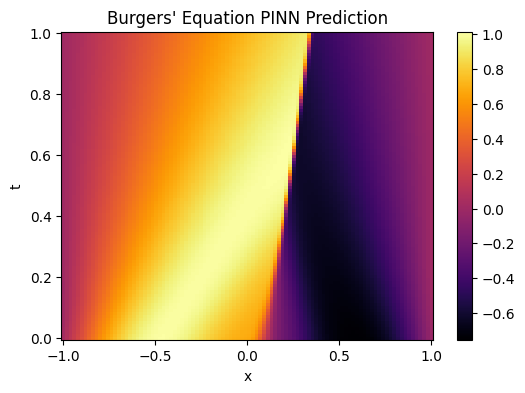

In [ ]:
# Exercise D Implementation
NU = 0.01 / np.pi

# 1. Update domain sampling
x_f_d = tf.convert_to_tensor(np.random.uniform(-1, 1, (N_COLLOCATION, 1)), dtype=tf.float32)
t_f_d = tf.convert_to_tensor(np.random.uniform(0, T, (N_COLLOCATION, 1)), dtype=tf.float32)

x_ic_d = tf.convert_to_tensor(np.random.uniform(-1, 1, (N_IC, 1)), dtype=tf.float32)
t_ic_d = tf.convert_to_tensor(np.zeros((N_IC, 1)), dtype=tf.float32)
u_ic_d = tf.convert_to_tensor(-np.sin(np.pi * x_ic_d.numpy()), dtype=tf.float32)

t_bc_d = tf.convert_to_tensor(np.random.uniform(0, T, (N_BC, 1)), dtype=tf.float32)
x_bc_left_d = tf.convert_to_tensor(np.full((N_BC, 1), -1.0), dtype=tf.float32)
x_bc_right_d = tf.convert_to_tensor(np.ones((N_BC, 1)), dtype=tf.float32)
u_bc_d = tf.convert_to_tensor(np.zeros((N_BC, 1)), dtype=tf.float32)

model_d = build_pinn(n_layers=6, n_units=40) # Slightly deeper network for nonlinearity
optimizer_d = tf.keras.optimizers.Adam(learning_rate=1e-3)

def burgers_residual(model, x, t):
    with tf.GradientTape(persistent=True) as tape2:
        tape2.watch([x, t])
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch([x, t])
            u = model(tf.concat([x, t], axis=1))
        u_x = tape1.gradient(u, x)
        u_t = tape1.gradient(u, t)
    u_xx = tape2.gradient(u_x, x)
    del tape1, tape2
    return u_t + u * u_x - NU * u_xx

@tf.function
def train_step_d():
    with tf.GradientTape() as tape:
        f_pred = burgers_residual(model_d, x_f_d, t_f_d)
        loss_pde = tf.reduce_mean(tf.square(f_pred))

        u_ic_pred = model_d(tf.concat([x_ic_d, t_ic_d], axis=1))
        loss_ic = tf.reduce_mean(tf.square(u_ic_pred - u_ic_d))

        u_bc_left_pred = model_d(tf.concat([x_bc_left_d, t_bc_d], axis=1))
        u_bc_right_pred = model_d(tf.concat([x_bc_right_d, t_bc_d], axis=1))
        loss_bc = tf.reduce_mean(tf.square(u_bc_left_pred - u_bc_d)) + \
                  tf.reduce_mean(tf.square(u_bc_right_pred - u_bc_d))

        loss = loss_pde + loss_ic + loss_bc

    grads = tape.gradient(loss, model_d.trainable_variables)
    optimizer_d.apply_gradients(zip(grads, model_d.trainable_variables))
    return loss

for epoch in range(3000):
    loss_d = train_step_d()
    if epoch % 500 == 0:
        print(f"Burgers Epoch {epoch:4d} | total loss: {loss_d:.4e}")

# Evaluate Burgers
x_grid_d = np.linspace(-1, 1, 100)
t_grid_d = np.linspace(0, 1, 100)
X_d, Tm_d = np.meshgrid(x_grid_d, t_grid_d)
xt_flat_d = np.stack([X_d.flatten(), Tm_d.flatten()], axis=1).astype(np.float32)

u_pred_d = model_d(xt_flat_d).numpy().reshape(100, 100)

plt.figure(figsize=(6, 4))
im = plt.pcolormesh(X_d, Tm_d, u_pred_d, shading='auto', cmap='inferno')
plt.colorbar(im)
plt.xlabel('x')
plt.ylabel('t')
plt.title("Burgers' Equation PINN Prediction")
plt.show()

### Exercise D: Nonlinear PDE (Burgers' Equation)
The plot visualizes the PINN's prediction for the viscous Burgers' equation. The heatmap clearly shows the development of a sharp, evolving shock wave over time, visible as the steep diagonal transition between the high (yellow) and low (black) regions. Because of this abrupt discontinuity, training a PINN for this nonlinear benchmark is much harder than for standard diffusion, often requiring mitigations like deeper networks or denser collocation points near the shock.

## Exercise E: Classical numerical baseline (FTCS)

We implement a classical numerical baseline using the explicit Forward-Time Central-Space (FTCS) finite-difference scheme to solve Eq. (2) and compare against the PINN performance.

FTCS Solver finished in 0.0377 seconds.


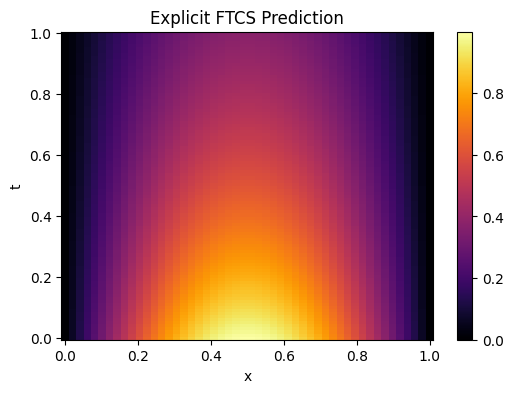

In [ ]:
# Exercise E Implementation
import time

nx = 50
nt = 5000
dx = L / (nx - 1)
dt = T / nt

# Stability condition check (Fourier Number <= 0.5)
assert (ALPHA * dt / dx**2) <= 0.5, "FTCS scheme is unstable"

x_fd = np.linspace(0, L, nx)
u_fd = np.zeros((nt, nx))

# IC
u_fd[0, :] = np.sin(np.pi * x_fd)

start_time = time.time()

# Time stepping
for n in range(0, nt - 1):
    # Vectorized FTCS interior updates
    u_fd[n+1, 1:-1] = u_fd[n, 1:-1] + (ALPHA * dt / dx**2) * (u_fd[n, 2:] - 2*u_fd[n, 1:-1] + u_fd[n, :-2])
    # BCs
    u_fd[n+1, 0] = 0.0
    u_fd[n+1, -1] = 0.0

fd_time = time.time() - start_time

print(f"FTCS Solver finished in {fd_time:.4f} seconds.")

# Extract grid to match earlier PINN visualization
T_indices = np.linspace(0, nt-1, 100, dtype=int)
u_fd_downsampled = u_fd[T_indices, :]

plt.figure(figsize=(6, 4))
X_fd, Tm_fd = np.meshgrid(x_fd, np.linspace(0, T, 100))
im = plt.pcolormesh(X_fd, Tm_fd, u_fd_downsampled, shading='auto', cmap='inferno')
plt.colorbar(im)
plt.xlabel('x')
plt.ylabel('t')
plt.title('Explicit FTCS Prediction')
plt.show()

Classical numerical methods like the FTCS scheme significantly outperform Physics-Informed Neural Networks (PINNs) in wall-clock time, accuracy, and memory efficiency when solving well-posed, low-dimensional, linear problems like the 1D heat equation. However, PINNs become genuinely advantageous in complex scenarios where traditional mesh-based solvers break down. Neural network approaches excel when solving PDEs on irregular domains, scaling to high-dimensional problems to avoid the curse of dimensionality, and tackling inverse problems such as recovering unknown physical parameters from sparse, noisy sensor data